# Régulation d’une chambre froide par logique floue

L’objectif est de déterminer la puissance frigorifique à partir de l’écart à la consigne de **3 °C** et de la durée d’ouverture des portes.

Les calculs sont réalisés avec NumPy et les graphiques avec Matplotlib.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

plt.rcParams.update({'figure.figsize': (9, 3.8), 'axes.grid': True,
                     'font.size': 11, 'grid.alpha': 0.25})

def tableau(entetes, lignes):
    texte = '| ' + ' | '.join(entetes) + ' |\n'
    texte += '| ' + ' | '.join(['---'] * len(entetes)) + ' |\n'
    texte += '\n'.join('| ' + ' | '.join(map(str, ligne)) + ' |' for ligne in lignes)
    display(Markdown(texte))

def triangle(x, a, b, c):
    x = np.asarray(x, dtype=float)
    return np.maximum(0., np.minimum((x-a)/(b-a), (c-x)/(c-b)))

def trapeze(x, a, b, c, d):
    x = np.asarray(x, dtype=float)
    # Les paramètres répétés définissent les épaulements, y compris aux bornes.
    gauche = np.ones_like(x) if a == b else (x-a)/(b-a)
    droite = np.ones_like(x) if c == d else (d-x)/(d-c)
    return np.where((x >= a) & (x <= d),
                    np.maximum(0., np.minimum(np.minimum(gauche, droite), 1.)), 0.)

ensembles_e = {
    'Faible': lambda x: trapeze(x, -2, -2, 0, 2),
    'Modéré': lambda x: triangle(x, 0, 3, 6),
    'Élevé': lambda x: trapeze(x, 4, 6, 8, 8)}
ensembles_d = {
    'Courte': lambda x: trapeze(x, 0, 0, 2, 4),
    'Moyenne': lambda x: triangle(x, 2, 5, 8),
    'Longue': lambda x: trapeze(x, 6, 8, 10, 10)}
ensembles_p = {
    'Économique': lambda x: triangle(x, 0, 20, 40),
    'Normale': lambda x: triangle(x, 30, 50, 70),
    'Intensive': lambda x: triangle(x, 60, 80, 100)}

## Partie 1 — Définition des ensembles flous
### Question 1 — Variables du système

**1.1.** L’écart est $e=T_{mesurée}-3$. Un écart négatif signifie simplement que la chambre est
plus froide que la consigne. Une petite variation peut résulter de l’inertie thermique ou d’un cycle
de refroidissement ; elle ne constitue pas nécessairement une anomalie. Un refroidissement excessif
peut néanmoins être indésirable selon les produits.

**1.2.** L’ouverture des portes renseigne sur l’apport de chaleur avant que celui-ci soit entièrement
visible sur la température mesurée. Elle permet donc d’anticiper une charge thermique et de distinguer
une variation ponctuelle d’un chargement prolongé.

**1.3.** Les entrées sont l’écart $e\in[-2,8]$ en °C et l’ouverture cumulée
$d\in[0,10]$ en minutes sur les dix dernières minutes. La sortie est la puissance
$p\in[0,100]$ en %. La **fuzzification** transforme les mesures en degrés d’appartenance.
La **défuzzification** transforme la conclusion floue agrégée en une puissance numérique.

### Question 2 — Fonctions d’appartenance

Pour un triangle de paramètres $a<b<c$ :
$$\mu_\triangle(x)=\max\left(0,\min\left(\frac{x-a}{b-a},\frac{c-x}{c-b}\right)\right).$$
Un trapèze monte linéairement de 0 à 1 sur $[a,b]$, reste à 1 sur $[b,c]$,
puis descend sur $[c,d]$. Les paramètres répétés aux bornes sont traités comme des épaulements.

**2.1.** Les trois graphiques suivants utilisent exactement les paramètres du sujet.

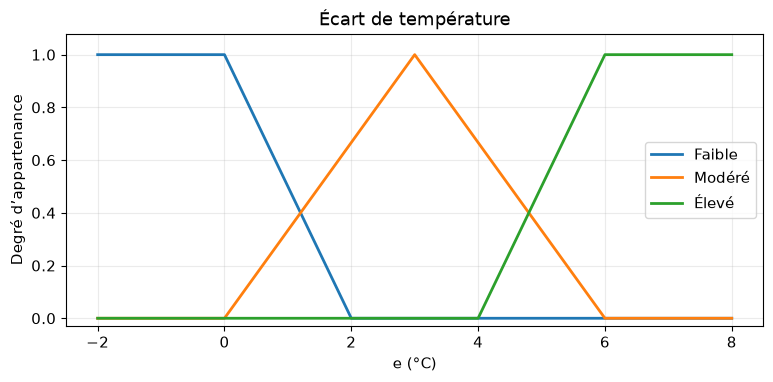

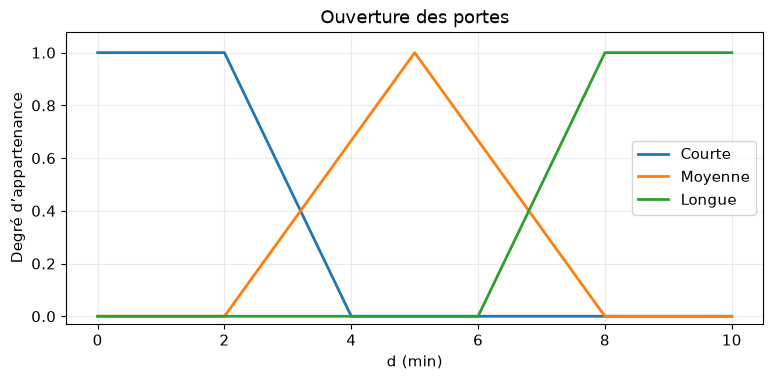

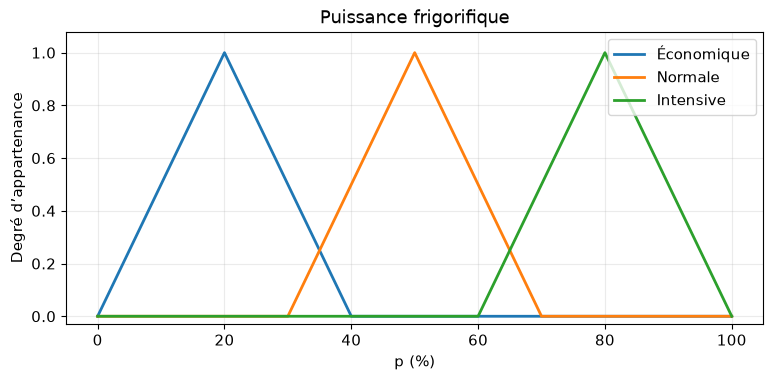

In [2]:
for univers, ensembles, titre, etiquette in [
    (np.linspace(-2, 8, 1001), ensembles_e, 'Écart de température', 'e (°C)'),
    (np.linspace(0, 10, 1001), ensembles_d, 'Ouverture des portes', 'd (min)'),
    (np.linspace(0, 100, 2001), ensembles_p, 'Puissance frigorifique', 'p (%)')]:
    fig, ax = plt.subplots()
    for nom, fonction in ensembles.items():
        ax.plot(univers, fonction(univers), label=nom, lw=2)
    ax.set(xlabel=etiquette, ylabel='Degré d’appartenance', title=titre, ylim=(-0.03, 1.08))
    ax.legend()
    plt.show()

**2.2.** Les ensembles se recouvrent afin de représenter des transitions progressives entre des
termes linguistiques. Une ouverture de 7 minutes est à la fois « moyenne » et « longue », avec
des degrés différents. Les degrés ne sont pas des probabilités et leur somme n’est pas forcément 1.

**2.3.** Le sommet à 80 % signifie que $\mu_{Intensive}(80)=1$ ; il ne fixe pas à lui seul
une borne supérieure aux valeurs représentées : $\mu_{Intensive}(90)=0{,}5$.
**Cependant, pour ce régulateur précis et la défuzzification par centre de gravité, la sortie ne
dépasse pas 80 %.** Un triangle Intensive tronqué reste symétrique autour de 80 % : son centre
de gravité vaut 80 %. Les autres conclusions ajoutent de la surface uniquement à sa gauche,
et ne peuvent donc déplacer ce centre vers la droite. Ainsi, la représentation admet des valeurs
supérieures à 80 %, mais le choix conjoint des conclusions et de cette défuzzification empêche
ici de recommander plus de 80 %. Une autre forme de sortie ou méthode de défuzzification
pourrait donner un résultat différent.

## Partie 2 — Fuzzification d’une situation réelle
### Question 3 — Incident à 14 h 30

**3.1.** $e=7-3=4\;°C$, et $d=7$ minutes.

**3.2.** Pour $e=4$ :

- Faible : au-delà du support $[-2,2]$, donc $\mu_F(4)=0$.
- Modéré : branche descendante, $\mu_M(4)=(6-4)/(6-3)=2/3$.
- Élevé : début de la montée, $\mu_E(4)=(4-4)/(6-4)=0$.

**3.3.** Pour $d=7$ :

- Courte : au-delà du support $[0,4]$, donc $\mu_C(7)=0$.
- Moyenne : branche descendante, $\mu_{Moy}(7)=(8-7)/(8-5)=1/3$.
- Longue : branche montante, $\mu_L(7)=(7-6)/(8-6)=1/2$.

**3.4.** Les six degrés sont vérifiés ci-dessous. L’écart est Modéré ; l’ouverture est simultanément
Moyenne et Longue.

In [3]:
def fuzzifier(e, d):
    if not (-2 <= e <= 8 and 0 <= d <= 10):
        raise ValueError('Mesures hors des univers du sujet.')
    return ({nom: float(f(e)) for nom, f in ensembles_e.items()},
            {nom: float(f(d)) for nom, f in ensembles_d.items()})

fe, fd = fuzzifier(4, 7)
tableau(['Variable', 'Ensemble', 'Degré'],
        [('e = 4 °C', k, f'{v:.6f}') for k, v in fe.items()] +
        [('d = 7 min', k, f'{v:.6f}') for k, v in fd.items()])

| Variable | Ensemble | Degré |
| --- | --- | --- |
| e = 4 °C | Faible | 0.000000 |
| e = 4 °C | Modéré | 0.666667 |
| e = 4 °C | Élevé | 0.000000 |
| d = 7 min | Courte | 0.000000 |
| d = 7 min | Moyenne | 0.333333 |
| d = 7 min | Longue | 0.500000 |

**3.5.** La durée de 7 minutes est connue : il n’y a pas ici d’incertitude aléatoire sur la mesure.
Le degré 0,5 exprime à quel point cette durée correspond au terme « Longue », selon la fonction
choisie. Une probabilité de 50 % décrirait l’incertitude concernant un événement ; elle ne décrit
pas l’appartenance graduelle d’une valeur connue à une catégorie imprécise.

## Partie 3 — Construction des règles de décision
### Question 4 — Base de règles

**4.1.** ET exige la satisfaction conjointe des deux conditions : avec le minimum, la moins
satisfaite limite la règle. OU suffit dès qu’une des conditions est satisfaite : avec le maximum,
la condition la plus satisfaite fixe l’activation.

In [4]:
# Numéro, catégorie d'écart, opérateur, catégorie d'ouverture, conclusion
regles = [
    ('R1', 'Faible', 'ET', 'Courte', 'Économique'),
    ('R2', 'Faible', 'ET', 'Longue', 'Normale'),
    ('R3', 'Modéré', 'ET', 'Moyenne', 'Normale'),
    ('R4', 'Modéré', 'ET', 'Longue', 'Intensive'),
    ('R5', 'Élevé', 'ET', 'Courte', 'Intensive'),
    ('R6', 'Élevé', 'ET', 'Longue', 'Intensive'),
    ('R7', 'Élevé', 'OU', 'Longue', 'Intensive')]

def activer(fe, fd, tnorme='minimum'):
    et = min if tnorme == 'minimum' else lambda a, b: a*b
    return {r: float(et(fe[ce], fd[cd]) if op == 'ET' else max(fe[ce], fd[cd]))
            for r, ce, op, cd, sortie in regles}

alpha = activer(fe, fd)
tableau(['Règle', 'Condition', 'Calcul', 'Activation', 'Conclusion'], [
    [r, f'{ce} {op} {cd}',
     f'{"min" if op == "ET" else "max"}({fe[ce]:.6f}, {fd[cd]:.6f})',
     f'{alpha[r]:.6f}', sortie] for r, ce, op, cd, sortie in regles])

| Règle | Condition | Calcul | Activation | Conclusion |
| --- | --- | --- | --- | --- |
| R1 | Faible ET Courte | min(0.000000, 0.000000) | 0.000000 | Économique |
| R2 | Faible ET Longue | min(0.000000, 0.500000) | 0.000000 | Normale |
| R3 | Modéré ET Moyenne | min(0.666667, 0.333333) | 0.333333 | Normale |
| R4 | Modéré ET Longue | min(0.666667, 0.500000) | 0.500000 | Intensive |
| R5 | Élevé ET Courte | min(0.000000, 0.000000) | 0.000000 | Intensive |
| R6 | Élevé ET Longue | min(0.000000, 0.500000) | 0.000000 | Intensive |
| R7 | Élevé OU Longue | max(0.000000, 0.500000) | 0.500000 | Intensive |

**4.2.** On obtient $(\alpha_1,\ldots,\alpha_7)=(0,0,1/3,1/2,0,0,1/2)$.

**4.3.** R1, R2, R5 et R6 sont inactives. Leur conclusion tronquée à 0 est nulle partout ;
elles n’apportent donc aucune surface à la sortie agrégée.

**4.4.** L’agrégation prescrite est un maximum, pas une addition. R4 et R7 recommandent toutes
deux Intensive à 0,5 : la hauteur résultante est $\max(0{,}5,0{,}5)=0{,}5$, et non 1.
Cela évite de compter deux fois une même conclusion, notamment avec des règles redondantes.

### Question 5 — Minimum et produit

In [5]:
alpha_produit = activer(fe, fd, 'produit')
tableau(['Règle', 'ET minimum / OU maximum', 'ET produit / OU maximum'],
        [[r, f'{alpha[r]:.6f}', f'{alpha_produit[r]:.6f}'] for r, *_ in regles])

| Règle | ET minimum / OU maximum | ET produit / OU maximum |
| --- | --- | --- |
| R1 | 0.000000 | 0.000000 |
| R2 | 0.000000 | 0.000000 |
| R3 | 0.333333 | 0.222222 |
| R4 | 0.500000 | 0.333333 |
| R5 | 0.000000 | 0.000000 |
| R6 | 0.000000 | 0.000000 |
| R7 | 0.500000 | 0.500000 |

**5.1–5.2.** Avec le produit, R1, R2, R5 et R6 restent nulles,
R3 vaut $(2/3)(1/3)=2/9\approx0{,}2222$ et R4 vaut $(2/3)(1/2)=1/3$.
Elles étaient respectivement à $1/3$ et $1/2$ avec le minimum.

**5.3.** Pour $a,b\in[0,1]$, $ab\leq\min(a,b)$ : multiplier par une valeur inférieure à 1
réduit le résultat. Plusieurs conditions partiellement satisfaites renforcent cette réduction.

**5.4.** R7 reste à $\max(0,1/2)=1/2$, car seul l’opérateur ET a changé.
Pour la suite, on revient au minimum pour ET.

## Partie 4 — Inférence de Mamdani
### Question 6 — Conclusions et agrégation

**6.1.** Les règles actives sont R3 : Normale à $1/3$ ; R4 : Intensive à $1/2$ ;
R7 : Intensive à $1/2$.

**6.2.** Pour chaque règle $i$, $\mu_i(p)=\min(\alpha_i,\mu_{conclusion_i}(p))$.
R4 et R7 produisent exactement la même courbe ; les styles et épaisseurs permettent de les repérer.

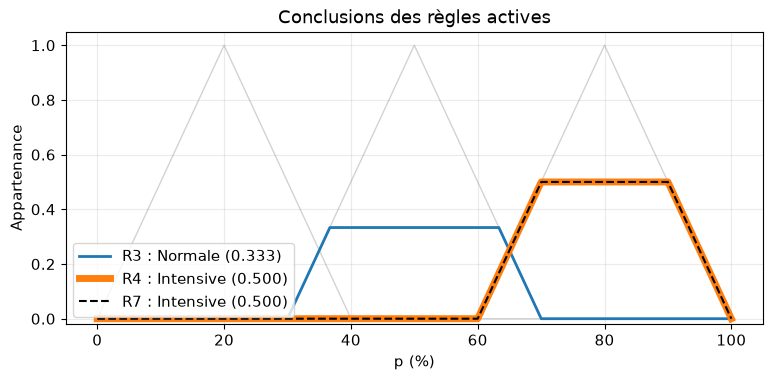

| Catégorie | Hauteur agrégée |
| --- | --- |
| Économique | 0.000000 |
| Normale | 0.333333 |
| Intensive | 0.500000 |

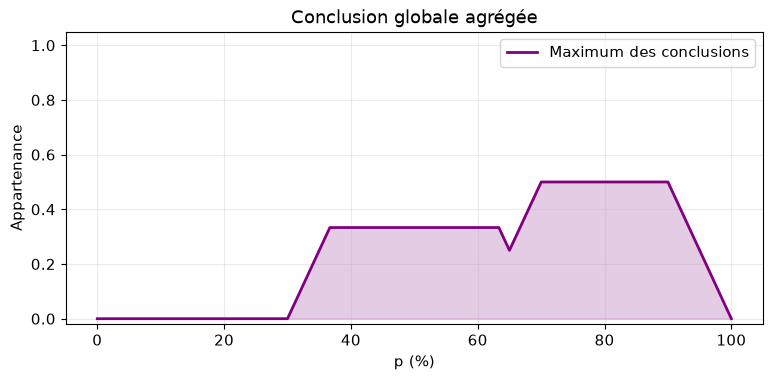

In [6]:
p = np.linspace(0, 100, 6001)  # Contient les cassures en tiers du cas étudié.
fig, ax = plt.subplots()
for nom, f in ensembles_p.items():
    ax.plot(p, f(p), color='gray', alpha=0.35, lw=1)
for r, style, couleur, largeur in [('R3', '-', 'tab:blue', 2),
                                    ('R4', '-', 'tab:orange', 5),
                                    ('R7', '--', 'black', 1.5)]:
    sortie = next(s for numero, *_, s in regles if numero == r)
    ax.plot(p, np.minimum(alpha[r], ensembles_p[sortie](p)),
            style, color=couleur, lw=largeur, label=f'{r} : {sortie} ({alpha[r]:.3f})')
ax.set(xlabel='p (%)', ylabel='Appartenance', title='Conclusions des règles actives', ylim=(-0.02, 1.05))
ax.legend()
plt.show()

def agreger(activations, grille):
    hauteurs = {s: max(activations[r] for r, *_, sortie in regles if sortie == s)
                for s in ensembles_p}
    courbes = {s: np.minimum(h, ensembles_p[s](grille)) for s, h in hauteurs.items()}
    globale = np.maximum.reduce(list(courbes.values()))
    return hauteurs, courbes, globale

hauteurs, conclusions, mu = agreger(alpha, p)
tableau(['Catégorie', 'Hauteur agrégée'], [[s, f'{h:.6f}'] for s, h in hauteurs.items()])
fig, ax = plt.subplots()
ax.plot(p, mu, color='purple', lw=2, label='Maximum des conclusions')
ax.fill_between(p, mu, color='purple', alpha=0.2)
ax.set(xlabel='p (%)', ylabel='Appartenance', title='Conclusion globale agrégée', ylim=(-0.02, 1.05))
ax.legend()
plt.show()

**6.3.** Les hauteurs finales sont Économique : 0 ; Normale : $1/3$ ; Intensive : $1/2$.

**6.4.** La courbe globale représentée ci-dessus est
$$\mu(p)=\max\left[\min(1/3,\mu_N(p)),\min(1/2,\mu_I(p))\right].$$
On peut aussi l’écrire explicitement :
$$\mu(p)=\begin{cases}
0 & 0\leq p\leq30,\\
(p-30)/20 & 30<p<110/3,\\
1/3 & 110/3\leq p\leq190/3,\\
(70-p)/20 & 190/3<p<65,\\
(p-60)/20 & 65\leq p<70,\\
1/2 & 70\leq p\leq90,\\
(100-p)/20 & 90<p\leq100.
\end{cases}$$

**6.5.** Chaque puissance a encore un degré d’appartenance : aucune valeur unique n’a été
sélectionnée. Il faut défuzzifier pour obtenir une consigne applicable au compresseur.

## Partie 5 — Défuzzification
### Question 7 — Centre de gravité

**7.1.** Le dénominateur $A=\int\mu(p)\,dp$ est l’aire de la conclusion floue.
Le numérateur $M=\int p\mu(p)\,dp$ est son premier moment par rapport à l’origine.
Le rapport $p^*=M/A$ donne l’abscisse de son centre de gravité, si $A>0$.

**7.2.** La fonction suivante intègre exactement chaque segment affine de la courbe échantillonnée.
Pour un segment de largeur $h$, d’ordonnée initiale $y_0$ et de variation $\Delta y$ :
$$A_i=h(y_0+y_1)/2,\qquad
M_i=x_0 A_i+h^2(y_0/2+\Delta y/3).$$
L’intégration est exacte lorsque la grille contient toutes les cassures, comme dans le cas étudié.

Aire A = 24.861111111
Moment M = 1674.305555556
Puissance recommandée = 67.346369 %
Fraction exacte : 12055/179 = 67.346369 %


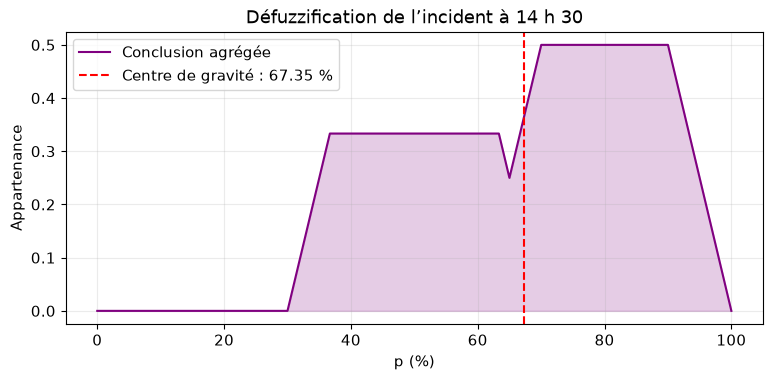

In [7]:
def centre_gravite(x, y):
    h = np.diff(x)
    y0, y1 = y[:-1], y[1:]
    aires = h * (y0 + y1) / 2
    moments = x[:-1] * aires + h**2 * (y0 / 2 + (y1-y0) / 3)
    aire, moment = float(aires.sum()), float(moments.sum())
    if aire <= 0:
        return np.nan, aire, moment
    return moment/aire, aire, moment

puissance, aire, moment = centre_gravite(p, mu)
print(f'Aire A = {aire:.9f}')
print(f'Moment M = {moment:.9f}')
print(f'Puissance recommandée = {puissance:.6f} %')
print(f'Fraction exacte : 12055/179 = {12055/179:.6f} %')

fig, ax = plt.subplots()
ax.plot(p, mu, color='purple', label='Conclusion agrégée')
ax.fill_between(p, mu, color='purple', alpha=0.2)
ax.axvline(puissance, color='red', linestyle='--', label=f'Centre de gravité : {puissance:.2f} %')
ax.set(xlabel='p (%)', ylabel='Appartenance', title='Défuzzification de l’incident à 14 h 30')
ax.legend()
plt.show()

Le calcul par morceaux donne $A=895/36$ et $M=60275/36$, d’où
$$\boxed{p^*=12055/179\simeq67{,}34637\ \%}.$$

**7.3.** La droite rouge du graphique situe cette puissance.

**7.4.** La moyenne des sommets $(20+50+80)/3=50$ % ignore les règles actives,
les hauteurs de troncature, les aires et les recouvrements. Même la moyenne des seuls sommets
actifs ne remplace pas en général le centre de gravité d’une agrégation par maximum.

## Partie 6 — Évaluation du régulateur
### Question 8 — Quatre situations

Le calcul suivant applique sans modification la même base de règles à chaque situation.

| Situation | e (°C) | Faible | Modéré | Élevé | Courte | Moyenne | Longue |
| --- | --- | --- | --- | --- | --- | --- | --- |
| A — Stockage stable | 0 | 1.0000 | 0.0000 | 0.0000 | 1.0000 | 0.0000 | 0.0000 |
| B — Chargement prolongé | 2 | 0.0000 | 0.6667 | 0.0000 | 0.0000 | 0.0000 | 1.0000 |
| C — Échauffement sans ouverture récente | 6 | 0.0000 | 0.0000 | 1.0000 | 1.0000 | 0.0000 | 0.0000 |
| D — Incident précédent | 4 | 0.0000 | 0.6667 | 0.0000 | 0.0000 | 0.3333 | 0.5000 |

| Situation | R1 | R2 | R3 | R4 | R5 | R6 | R7 | Puissance (%) |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| A — Stockage stable | 1.0000 | 0.0000 | 0.0000 | 0.0000 | 0.0000 | 0.0000 | 0.0000 | 20.00000 |
| B — Chargement prolongé | 0.0000 | 0.0000 | 0.0000 | 0.6667 | 0.0000 | 0.0000 | 1.0000 | 80.00000 |
| C — Échauffement sans ouverture récente | 0.0000 | 0.0000 | 0.0000 | 0.0000 | 1.0000 | 0.0000 | 1.0000 | 80.00000 |
| D — Incident précédent | 0.0000 | 0.0000 | 0.3333 | 0.5000 | 0.0000 | 0.0000 | 0.5000 | 67.34637 |

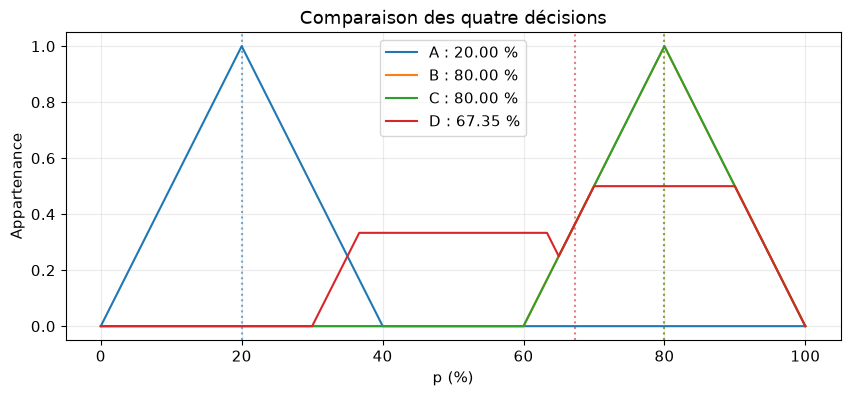

In [8]:
def regulateur(temperature, ouverture):
    e = temperature - 3
    fe, fd = fuzzifier(e, ouverture)
    activations = activer(fe, fd)
    hauteurs, _, globale = agreger(activations, p)
    valeur, aire, moment = centre_gravite(p, globale)
    return dict(e=e, fe=fe, fd=fd, alpha=activations, hauteurs=hauteurs,
                mu=globale, puissance=valeur)

situations = [('A — Stockage stable', 3, 1), ('B — Chargement prolongé', 5, 9),
              ('C — Échauffement sans ouverture récente', 9, 1),
              ('D — Incident précédent', 7, 7)]
resultats = {nom: regulateur(t, d) for nom, t, d in situations}
tableau(['Situation', 'e (°C)', 'Faible', 'Modéré', 'Élevé', 'Courte', 'Moyenne', 'Longue'],
        [[nom, r['e']] + [f'{v:.4f}' for v in [*r['fe'].values(), *r['fd'].values()]]
        for nom, r in resultats.items()])
tableau(['Situation'] + [r for r, *_ in regles] + ['Puissance (%)'],
        [[nom] + [f'{v:.4f}' for v in r['alpha'].values()] + [f"{r['puissance']:.5f}"]
        for nom, r in resultats.items()])

fig, ax = plt.subplots(figsize=(10, 4))
for nom, r in resultats.items():
    ligne, = ax.plot(p, r['mu'], label=f"{nom[0]} : {r['puissance']:.2f} %")
    ax.axvline(r['puissance'], color=ligne.get_color(), linestyle=':', alpha=0.6)
ax.set(xlabel='p (%)', ylabel='Appartenance', title='Comparaison des quatre décisions')
ax.legend()
plt.show()

**8.1–8.3. Détail des résultats :**

| Situation | Appartenances non nulles | Règles actives | Puissance |
|---|---|---|---|
| A | Faible = 1 ; Courte = 1 | R1 = 1 | 20 % |
| B | Modéré = 2/3 ; Longue = 1 | R4 = 2/3 ; R7 = 1 | 80 % |
| C | Élevé = 1 ; Courte = 1 | R5 = 1 ; R7 = 1 | 80 % |
| D | Modéré = 2/3 ; Moyenne = 1/3 ; Longue = 1/2 | R3 = 1/3 ; R4 = 1/2 ; R7 = 1/2 | ≈ 67,35 % |

**8.4.** A reçoit une puissance économique, tandis que B et C déclenchent une puissance intensive
pour deux raisons différentes : ouverture prolongée ou température élevée. D reçoit une puissance
intermédiaire plus élevée que A. Ces quatre décisions sont qualitativement cohérentes. Elles ne
suffisent toutefois pas à prouver une bonne régulation dynamique : le modèle thermique, l’évolution
de la température, l’énergie consommée et les contraintes du compresseur ne sont pas simulés.

**8.5. Faiblesses de la base proposée :**

- **Couverture incomplète.** Avec $e=0$ et $d=5$, seuls Faible et Moyenne valent 1.
  Aucune règle ne s’active : l’aire agrégée est nulle et le centre de gravité est indéfini.
  Le problème existe aussi pour un écart Modéré et une ouverture Courte sans autre condition active.
  Il faut compléter les règles et prévoir explicitement un comportement de repli.
- **Redondance.** R7 subsume R5 et R6 : $\max(\mu_E,\mu_L)$ est toujours au moins aussi grand
  que $\min(\mu_E,\mu_C)$ et $\min(\mu_E,\mu_L)$. R7 subsume aussi R4 puisque
  $\min(\mu_M,\mu_L)\leq\mu_L$. Ces règles ne modifient donc pas la sortie agrégée en présence de R7.
- **Puissances extrêmes indisponibles au centre de gravité.** Avec ces triangles symétriques,
  les sorties définies sont comprises entre 20 % et 80 %. Même à température inférieure à la
  consigne, R1 peut maintenir 20 % de puissance. Une sortie « Arrêt » et une sortie à épaulement
  proche de 100 % pourraient être étudiées selon les besoins réels.

Le test suivant rend visible le défaut de couverture sans inventer une consigne lorsque le modèle
ne donne aucune conclusion.

In [9]:
sans_regle = regulateur(3, 5)  # e = 0, d = 5
print('Activations :', sans_regle['alpha'])
print('Puissance :', sans_regle['puissance'])
print('NaN signifie : centre de gravité indéfini, aucune règle active.')

Activations : {'R1': 0.0, 'R2': 0.0, 'R3': 0.0, 'R4': 0.0, 'R5': 0.0, 'R6': 0.0, 'R7': 0.0}
Puissance : nan
NaN signifie : centre de gravité indéfini, aucune règle active.


## Partie 7 — Amélioration du système
### Question 9 — Ajouter la vitesse d’évolution de la température

**9.1.** $v=\Delta T/\Delta t$ renseigne sur la tendance : à $e$ et $d$ identiques,
une température qui monte rapidement peut nécessiter une action renforcée, tandis qu’une température
qui descend indique que le refroidissement agit déjà. Cette information peut réduire le retard
de réaction et le risque de sur-refroidissement.

**9.2. Proposition de fonctions d’appartenance.** Les valeurs suivantes sont des hypothèses de
conception à ajuster avec des mesures réelles ; elles ne sont pas imposées par le sujet.
Sur $v\in[-1,1]$ °C/min :

| Ensemble | Type | Paramètres (°C/min) |
|---|---|---|
| Baisse | Trapèze à épaulement | [-1 ; -1 ; -0,2 ; 0] |
| Stable | Triangle | [-0,2 ; 0 ; 0,2] |
| Hausse | Trapèze à épaulement | [0 ; 0,2 ; 1 ; 1] |

La vitesse serait calculée sur une fenêtre temporelle adaptée et filtrée pour éviter que le bruit
de mesure ne provoque des changements de puissance injustifiés.

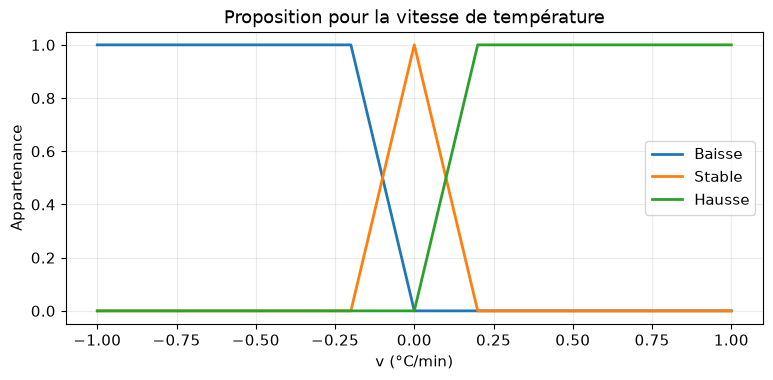

In [10]:
v = np.linspace(-1, 1, 1001)
ensembles_v = {'Baisse': trapeze(v, -1, -1, -0.2, 0),
               'Stable': triangle(v, -0.2, 0, 0.2),
               'Hausse': trapeze(v, 0, 0.2, 1, 1)}
fig, ax = plt.subplots()
for nom, degres in ensembles_v.items():
    ax.plot(v, degres, label=nom, lw=2)
ax.set(xlabel='v (°C/min)', ylabel='Appartenance', title='Proposition pour la vitesse de température')
ax.legend()
plt.show()

**9.3. Proposition de nouvelles règles :**

| Règle | Condition (ET = minimum) | Conclusion |
|---|---|---|
| N1 | Écart Modéré ET ouverture Courte ET vitesse Hausse | Intensive |
| N2 | Écart Modéré ET ouverture Courte ET vitesse Baisse | Économique |
| N3 | Écart Modéré ET ouverture Courte ET vitesse Stable | Normale |
| N4 | Écart Faible ET ouverture Moyenne ET vitesse Stable | Économique |

Les trois premières règles distinguent trois tendances pour les mêmes mesures $e,d$ et couvrent
une combinaison absente du modèle initial. La quatrième traite une autre lacune. Ces exemples ne
forment pas encore une base complète. Pour modérer une décision déjà imposée par R7, il faudrait
**réviser R7** ou lui ajouter une condition sur la vitesse : ajouter une règle économique ne retire
pas une conclusion intensive déjà présente dans une agrégation par maximum.

**9.4.** La fuzzification calcule trois degrés supplémentaires pour $v$. Une règle à trois
conditions reçoit une activation telle que
$$\alpha_{N1}=\min(\mu_{Modéré}(e),\mu_{Courte}(d),\mu_{Hausse}(v)).$$
La troncature, l’agrégation maximum et la défuzzification restent identiques. Une grille exhaustive
de trois entrées à trois catégories comporte jusqu’à $3^3=27$ combinaisons, contre $3^2=9$
auparavant. Il faut donc vérifier la couverture, les conflits et les décisions sur l’ensemble du domaine.

**9.5.** Un régulateur flou dépend de règles choisies, de capteurs et d’un logiciel qui peuvent
être incomplets ou défaillants. Il ne garantit pas à lui seul le respect des contraintes sanitaires.
Des alarmes et protections indépendantes doivent détecter les températures excessives, les pannes
et les mesures incohérentes, et déclencher les procédures prévues. La consigne de régulation de
3 °C ne doit pas être confondue avec un seuil sanitaire universel : les limites et temporisations
doivent être définies selon les produits stockés et les exigences applicables.